
# TermoAtiva — Inteligência Artificial & Machine Learning

**FIAP | Global Solution 2026.2 | CitizenTech**

## Objetivo

Desenvolver um modelo de Machine Learning capaz de classificar o nível de risco térmico ambiental, contribuindo para a prevenção dos impactos de ondas de calor extremo e ilhas de calor urbanas.

A solução é destinada a trabalhadores a céu aberto, entregadores, garis, idosos, pedestres e agentes comunitários.

## Abordagem

- **Algoritmo:** Regressão Logística
- **Tipo:** Classificação binária
- **Target:** `nivel_alerta_ambiental`
- **Classe 0:** Sem alerta crítico pelo critério ambiental adotado
- **Classe 1:** Risco térmico crítico

A referência para classificação será a metodologia do índice de calor da NOAA/NWS.

O modelo não realiza diagnósticos médicos nem avalia a saúde individual dos cidadãos.

## Fonte dos dados

INMET — Instituto Nacional de Meteorologia

https://portal.inmet.gov.br/dadoshistoricos

## ODS relacionados

- ODS 3 — Saúde e Bem-Estar
- ODS 10 — Redução das Desigualdades
- ODS 11 — Cidades e Comunidades Sustentáveis


In [1]:
# Bibliotecas para manipulação e análise de dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Bibliotecas para acessar o dataset do INMET
import requests
import zipfile
import unicodedata
from pathlib import Path

# Visualização de tabelas no Google Colab
from IPython.display import display

print("Bibliotecas importadas com sucesso!")
print("Versão do Pandas:", pd.__version__)
print("Versão do NumPy:", np.__version__)


Bibliotecas importadas com sucesso!
Versão do Pandas: 2.2.3
Versão do NumPy: 2.4.6


In [2]:
# Configuração do dataset
ANO = 2025

URL_INMET = (
    f"https://portal.inmet.gov.br/uploads/"
    f"dadoshistoricos/{ANO}.zip"
)

arquivo_zip = Path(f"/content/inmet_{ANO}.zip")

# Verifica se o arquivo já foi baixado
if not arquivo_zip.exists():

    print("Iniciando download do INMET...")

    try:
        resposta = requests.get(
            URL_INMET,
            stream=True,
            timeout=(20, 120),
            headers={"User-Agent": "Mozilla/5.0"}
        )

        resposta.raise_for_status()

        total_bytes = 0

        with open(arquivo_zip, "wb") as arquivo:
            for bloco in resposta.iter_content(
                chunk_size=1024 * 1024
            ):
                if bloco:
                    arquivo.write(bloco)
                    total_bytes += len(bloco)

        print(
            f"Download concluído: "
            f"{total_bytes / 1024**2:.1f} MB"
        )

    except requests.RequestException as erro:
        print("Download automático não disponível.")
        print("Detalhes:", erro)

        arquivo_zip.unlink(missing_ok=True)

        print("Selecione manualmente o ZIP de 2025.")

        from google.colab import files

        enviados = files.upload()

        if not enviados:
            raise RuntimeError("Nenhum arquivo enviado.")

        arquivo_zip = Path(
            "/content/" + next(iter(enviados))
        )

# Confere se o arquivo realmente é um ZIP válido
if not zipfile.is_zipfile(arquivo_zip):
    raise ValueError("O arquivo não é um ZIP válido.")

print("Dataset disponível:", arquivo_zip.name)


Iniciando download do INMET...
Download concluído: 86.7 MB
Dataset disponível: inmet_2025.zip


In [3]:
# Abre o arquivo ZIP sem extrair tudo
pacote = zipfile.ZipFile(arquivo_zip)

# Lista os arquivos CSV encontrados
arquivos_csv = [
    nome for nome in pacote.namelist()
    if nome.lower().endswith(".csv")
]

print("Quantidade de arquivos CSV:", len(arquivos_csv))

# Função auxiliar para normalizar nomes
def normalizar(texto):
    return (
        unicodedata.normalize("NFKD", texto)
        .encode("ascii", "ignore")
        .decode("ascii")
        .upper()
    )

# Procura pela estação automática A701
estacoes_a701 = [
    nome for nome in arquivos_csv
    if "_A701_" in normalizar(nome)
]

if not estacoes_a701:
    print("A701 não encontrada.")
    print("Exemplos de arquivos disponíveis:")
    print(*arquivos_csv[:10], sep="\n")

    raise ValueError(
        "Verifique o conteúdo do ZIP antes de continuar."
    )

# Seleciona o arquivo da estação
arquivo_estacao = estacoes_a701[0]

print("\nEstação selecionada:")
print(arquivo_estacao)

# Exibe os metadados originais da estação
print("\nMetadados do INMET:")

with pacote.open(arquivo_estacao) as arquivo:
    for _ in range(8):
        linha = arquivo.readline()
        print(linha.decode("latin1").strip())


Quantidade de arquivos CSV: 594

Estação selecionada:
2025/INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2025_A_31-12-2025.CSV

Metadados do INMET:
REGIAO:;SE
UF:;SP
ESTACAO:;SAO PAULO - MIRANTE
CODIGO (WMO):;A701
LATITUDE:;-23,4962888
LONGITUDE:;-46,6200666
ALTITUDE:;785,64
DATA DE FUNDACAO:;25/07/06


In [4]:
# Carrega o CSV da estação selecionada
with pacote.open(arquivo_estacao) as arquivo:

    df_bruto = pd.read_csv(
        arquivo,
        sep=";",
        encoding="latin1",
        skiprows=8,
        dtype=str
    )

# Remove espaços desnecessários dos nomes
df_bruto.columns = [
    coluna.strip()
    for coluna in df_bruto.columns
]

print("Dimensões do dataset:", df_bruto.shape)

print("\nColunas encontradas:")
for coluna in df_bruto.columns:
    print("-", coluna)

print("\nPrimeiras 5 linhas:")
display(df_bruto.head())


Dimensões do dataset: (8760, 20)

Colunas encontradas:
- Data
- Hora UTC
- PRECIPITAÇÃO TOTAL, HORÁRIO (mm)
- PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)
- PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)
- PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)
- RADIACAO GLOBAL (Kj/m²)
- TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)
- TEMPERATURA DO PONTO DE ORVALHO (°C)
- TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)
- TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)
- TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)
- TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)
- UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)
- UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)
- UMIDADE RELATIVA DO AR, HORARIA (%)
- VENTO, DIREÇÃO HORARIA (gr) (° (gr))
- VENTO, RAJADA MAXIMA (m/s)
- VENTO, VELOCIDADE HORARIA (m/s)
- Unnamed: 19

Primeiras 5 linhas:


,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),RADIACAO GLOBAL (Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",TEMPERATURA DO PONTO DE ORVALHO (°C),TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C),UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),"UMIDADE RELATIVA DO AR, HORARIA (%)","VENTO, DIREÇÃO HORARIA (gr) (° (gr))","VENTO, RAJADA MAXIMA (m/s)","VENTO, VELOCIDADE HORARIA (m/s)",Unnamed: 19
0,2025/01/01,0000 UTC,0,"925,1","925,2","924,8",NaN,"21,2","16,9","21,6","21,1","16,9","16,6",76,74,76,153,"4,1","1,8",NaN
1,2025/01/01,0100 UTC,0,"925,2","925,3","925,1",NaN,"21,1","17,3","21,4","21,1","17,3","16,8",79,76,79,133,"5,1","2,1",NaN
2,2025/01/01,0200 UTC,0,"925,2","925,5","925,2",NaN,"20,5","17,4","21,1","20,5","17,4","17,2",82,79,82,120,5,"1,5",NaN
3,2025/01/01,0300 UTC,0,"924,9","925,3","924,9",NaN,"20,7","17,3","20,8","20,4","17,6","17,3",83,81,81,137,"6,8","1,4",NaN
4,2025/01/01,0400 UTC,0,"924,4","924,9","924,4",NaN,"20,2","17,3","20,7",20,"17,3","16,9",84,80,83,135,"5,2","1,7",NaN


In [5]:
# Localiza as colunas pelos nomes originais
def encontrar_coluna(termos, obrigatoria=True):
    for coluna in df_bruto.columns:
        nome = normalizar(coluna)

        if all(termo in nome for termo in termos):
            return coluna

    if obrigatoria:
        raise ValueError(
            f"Coluna não encontrada: {termos}"
        )

    return None


col_data = encontrar_coluna(["DATA"])
col_hora = encontrar_coluna(["HORA", "UTC"])

col_temp = encontrar_coluna([
    "TEMPERATURA DO AR",
    "BULBO SECO",
    "HORARIA"
])

col_umidade = encontrar_coluna([
    "UMIDADE RELATIVA DO AR",
    "HORARIA"
])

col_radiacao = encontrar_coluna(
    ["RADIACAO GLOBAL"],
    obrigatoria=False
)

# Converte texto numérico para valores decimais
def converter_numero(serie):
    return pd.to_numeric(
        serie.str.strip().str.replace(
            ",", ".", regex=False
        ),
        errors="coerce"
    ).replace(-9999, np.nan)


# Processa datas e horas UTC
datas = pd.to_datetime(
    df_bruto[col_data].str.replace(
        "/", "-", regex=False
    ),
    errors="coerce"
)

horas_texto = df_bruto[col_hora].str.extract(
    r"(\d{2}):?(\d{2})"
)

horas = pd.to_numeric(
    horas_texto[0], errors="coerce"
)

minutos = pd.to_numeric(
    horas_texto[1], errors="coerce"
)

data_hora_utc = (
    datas
    + pd.to_timedelta(horas, unit="h")
    + pd.to_timedelta(minutos, unit="m")
).dt.tz_localize("UTC")

data_hora_local = data_hora_utc.dt.tz_convert(
    "America/Sao_Paulo"
)

# Cria o DataFrame de trabalho
df = pd.DataFrame({
    "data_hora_utc": data_hora_utc,
    "data_hora_local": data_hora_local,
    "temperatura_ar_celsius": converter_numero(
        df_bruto[col_temp]
    ),
    "umidade_relativa_ar": converter_numero(
        df_bruto[col_umidade]
    )
})

# Hora de 1 a 24, conforme especificação
# Meia-noite é representada por 24
df["hora_do_dia"] = (
    data_hora_local.dt.hour.replace({0: 24})
)

if col_radiacao:
    df["radiacao_global_kj_m2"] = converter_numero(
        df_bruto[col_radiacao]
    )
else:
    print("Radiação global não disponível na estação.")

print("Dataset organizado:")
display(df.head())


Dataset organizado:


,data_hora_utc,data_hora_local,temperatura_ar_celsius,umidade_relativa_ar,hora_do_dia,radiacao_global_kj_m2
0,2025-01-01 00:00:00+00:00,2024-12-31 21:00:00-03:00,21.2,76.0,21,NaN
1,2025-01-01 01:00:00+00:00,2024-12-31 22:00:00-03:00,21.1,79.0,22,NaN
2,2025-01-01 02:00:00+00:00,2024-12-31 23:00:00-03:00,20.5,82.0,23,NaN
3,2025-01-01 03:00:00+00:00,2025-01-01 00:00:00-03:00,20.7,81.0,24,NaN
4,2025-01-01 04:00:00+00:00,2025-01-01 01:00:00-03:00,20.2,83.0,1,NaN


In [6]:
print("=== QUALIDADE DOS DADOS ===")

print("\nQuantidade de registros:")
print(len(df))

print("\nPeríodo disponível:")
print("Início:", df["data_hora_local"].min())
print("Fim:", df["data_hora_local"].max())

print("\nValores ausentes:")
display(df.isna().sum().to_frame("Ausentes"))

print("\nEstatísticas descritivas:")
display(df.describe())

# Verifica registros com o mesmo horário
duplicados = df["data_hora_utc"].duplicated().sum()

print("\nHorários duplicados:", duplicados)

# Confere valores fisicamente suspeitos
temperaturas_invalidas = (
    (df["temperatura_ar_celsius"] < -20)
    | (df["temperatura_ar_celsius"] > 55)
).sum()

umidades_invalidas = (
    (df["umidade_relativa_ar"] < 0)
    | (df["umidade_relativa_ar"] > 100)
).sum()

print("\nTemperaturas suspeitas:",
      temperaturas_invalidas)

print("Umidades inválidas:",
      umidades_invalidas)

if "radiacao_global_kj_m2" in df.columns:
    print(
        "Valores negativos de radiação:",
        (df["radiacao_global_kj_m2"] < 0).sum()
    )


=== QUALIDADE DOS DADOS ===

Quantidade de registros:
8760

Período disponível:
Início: 2024-12-31 21:00:00-03:00
Fim: 2025-12-31 20:00:00-03:00

Valores ausentes:


,Ausentes
data_hora_utc,0
data_hora_local,0
temperatura_ar_celsius,47
umidade_relativa_ar,47
hora_do_dia,0
radiacao_global_kj_m2,4061



Estatísticas descritivas:


,temperatura_ar_celsius,umidade_relativa_ar,hora_do_dia,radiacao_global_kj_m2
count,8713.000000,8713.000000,8760.000000,4699.000000
mean,20.432170,68.263285,12.500000,1266.962588
std,4.804337,16.892302,6.922582,1091.801230
min,6.200000,12.000000,1.000000,0.000000
25%,16.900000,57.000000,6.750000,244.450000
50%,20.200000,73.000000,12.500000,1042.300000
75%,23.400000,81.000000,18.250000,2158.100000
max,35.900000,100.000000,24.000000,3995.700000



Horários duplicados: 0

Temperaturas suspeitas: 0
Umidades inválidas: 0
Valores negativos de radiação: 0


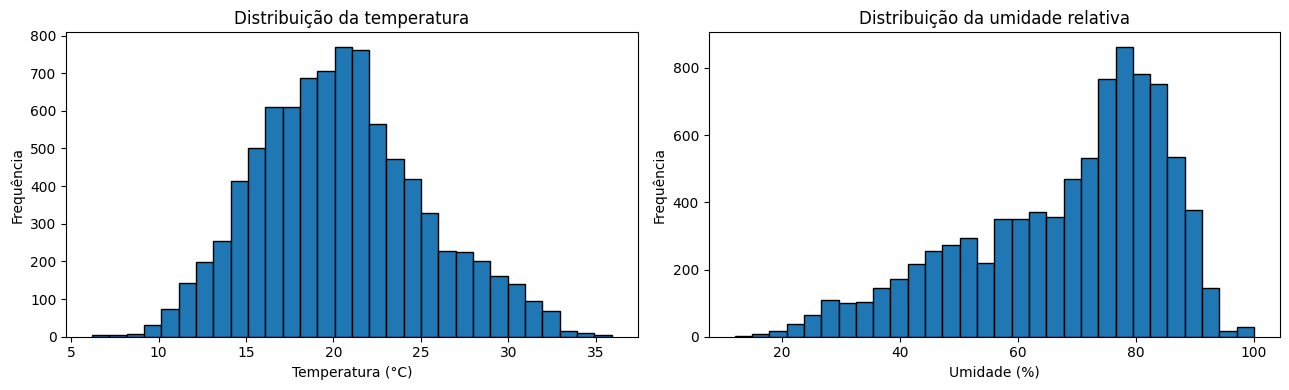

In [7]:
fig, eixos = plt.subplots(
    1, 2, figsize=(13, 4)
)

# Distribuição de temperatura
eixos[0].hist(
    df["temperatura_ar_celsius"].dropna(),
    bins=30,
    edgecolor="black"
)

eixos[0].set_title(
    "Distribuição da temperatura"
)
eixos[0].set_xlabel("Temperatura (°C)")
eixos[0].set_ylabel("Frequência")

# Distribuição da umidade
eixos[1].hist(
    df["umidade_relativa_ar"].dropna(),
    bins=30,
    edgecolor="black"
)

eixos[1].set_title(
    "Distribuição da umidade relativa"
)
eixos[1].set_xlabel("Umidade (%)")
eixos[1].set_ylabel("Frequência")

plt.tight_layout()
plt.show()


Disponibilidade de radiação por horário:


,hora_do_dia,total,disponiveis,media,ausentes,percentual_ausente
0,1,365,2,0.250000,363,99.45
1,2,365,3,0.166667,362,99.18
2,3,365,7,0.728571,358,98.08
3,4,365,5,0.840000,360,98.63
4,5,365,6,0.650000,359,98.36
5,6,365,137,34.107299,228,62.47
6,7,365,361,167.174792,4,1.10
7,8,365,361,589.015235,4,1.10
8,9,365,361,1211.028532,4,1.10
9,10,365,364,1820.495055,1,0.27


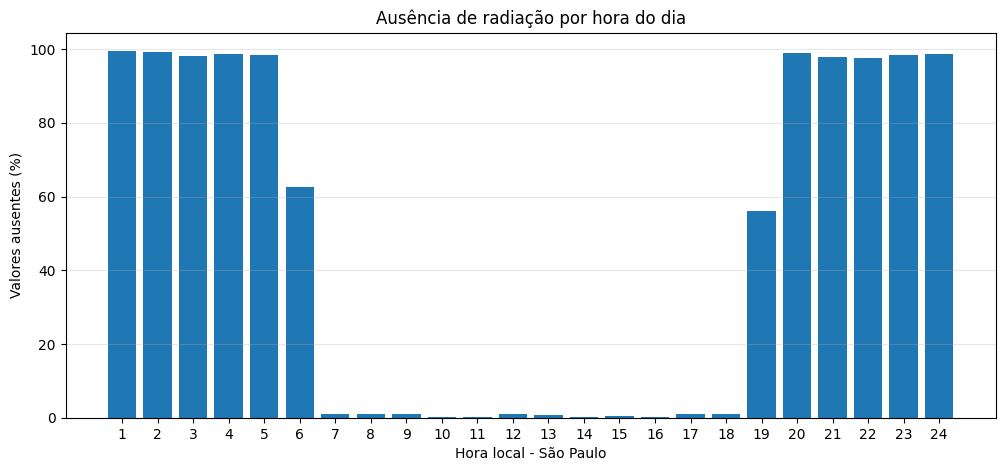

Registros originais: 8760
Com temperatura e umidade: 8713
Com as três medições: 4699


In [8]:

# ===========================================
# TERMOATIVA - ANÁLISE DA RADIAÇÃO SOLAR
# ===========================================

# Verifica disponibilidade de radiação por hora
radiacao_por_hora = (
    df.groupby("hora_do_dia")["radiacao_global_kj_m2"]
    .agg(
        total="size",
        disponiveis="count",
        media="mean"
    )
    .reset_index()
    .sort_values("hora_do_dia")
)

radiacao_por_hora["ausentes"] = (
    radiacao_por_hora["total"]
    - radiacao_por_hora["disponiveis"]
)

radiacao_por_hora["percentual_ausente"] = (
    radiacao_por_hora["ausentes"]
    / radiacao_por_hora["total"] * 100
).round(2)

print("Disponibilidade de radiação por horário:")
display(radiacao_por_hora)

# Gráfico de valores ausentes por hora
plt.figure(figsize=(12, 5))

plt.bar(
    radiacao_por_hora["hora_do_dia"],
    radiacao_por_hora["percentual_ausente"]
)

plt.title("Ausência de radiação por hora do dia")
plt.xlabel("Hora local - São Paulo")
plt.ylabel("Valores ausentes (%)")
plt.xticks(range(1, 25))
plt.grid(axis="y", alpha=0.3)

plt.show()

# Verifica quantidade de registros completos
variaveis_basicas = [
    "temperatura_ar_celsius",
    "umidade_relativa_ar"
]

variaveis_com_radiacao = variaveis_basicas + [
    "radiacao_global_kj_m2"
]

df_basico = df.dropna(
    subset=variaveis_basicas
).copy()

df_completo = df.dropna(
    subset=variaveis_com_radiacao
).copy()

print("Registros originais:", len(df))
print("Com temperatura e umidade:", len(df_basico))
print("Com as três medições:", len(df_completo))


In [9]:

# ===========================================
# TERMOATIVA - ÍNDICE DE CALOR NOAA
# ===========================================

import math

def calcular_indice_calor(temp_c, umidade):
    """
    Calcula o Heat Index seguindo o procedimento
    do National Weather Service (NOAA).

    Entrada:
      temp_c: temperatura em Celsius
      umidade: umidade relativa em porcentagem

    Saída:
      índice de calor em Celsius
    """

    # A fórmula original utiliza Fahrenheit
    T = (temp_c * 9 / 5) + 32
    RH = umidade

    # Fórmula simplificada do NWS
    HI_simples = 0.5 * (
        T + 61.0 + (T - 68.0) * 1.2 + RH * 0.094
    )

    HI = (HI_simples + T) / 2

    # Equação de Rothfusz para HI >= 80°F
    if HI >= 80:

        HI = (
            -42.379
            + 2.04901523 * T
            + 10.14333127 * RH
            - 0.22475541 * T * RH
            - 0.00683783 * T**2
            - 0.05481717 * RH**2
            + 0.00122874 * T**2 * RH
            + 0.00085282 * T * RH**2
            - 0.00000199 * T**2 * RH**2
        )

        # Ajuste para baixa umidade
        if RH < 13 and 80 <= T <= 112:
            ajuste = (
                (13 - RH) / 4
                * math.sqrt((17 - abs(T - 95)) / 17)
            )
            HI -= ajuste

        # Ajuste para umidade elevada
        elif RH > 85 and 80 <= T <= 87:
            ajuste = (
                (RH - 85) / 10
                * ((87 - T) / 5)
            )
            HI += ajuste

    return (HI - 32) * 5 / 9


# Preserva apenas linhas com temperatura e
# umidade válidas, já verificadas anteriormente
df_modelo = df_basico.copy()

# Calcula o índice para cada registro
df_modelo["indice_calor_celsius"] = [
    calcular_indice_calor(temp, umidade)
    for temp, umidade in zip(
        df_modelo["temperatura_ar_celsius"],
        df_modelo["umidade_relativa_ar"]
    )
]

print("Índice de calor calculado!")

display(df_modelo[[
    "temperatura_ar_celsius",
    "umidade_relativa_ar",
    "indice_calor_celsius"
]].head(10).round(2))


Índice de calor calculado!


,temperatura_ar_celsius,umidade_relativa_ar,indice_calor_celsius
0,21.2,76.0,21.28
1,21.1,79.0,21.21
2,20.5,82.0,20.62
3,20.7,81.0,20.82
4,20.2,83.0,20.32
5,19.7,85.0,19.82
6,19.6,85.0,19.72
7,19.3,86.0,19.42
8,19.0,87.0,19.11
9,19.1,88.0,19.23


=== DISTRIBUIÇÃO DAS CLASSES ===
Classe 0 - Sem alerta crítico: 8713
Classe 1 - Risco crítico: 0

Percentual por classe:
nivel_alerta_ambiental
0    100.0
1      0.0
Name: count, dtype: float64

Maior índice de calor registrado:
34.73 °C


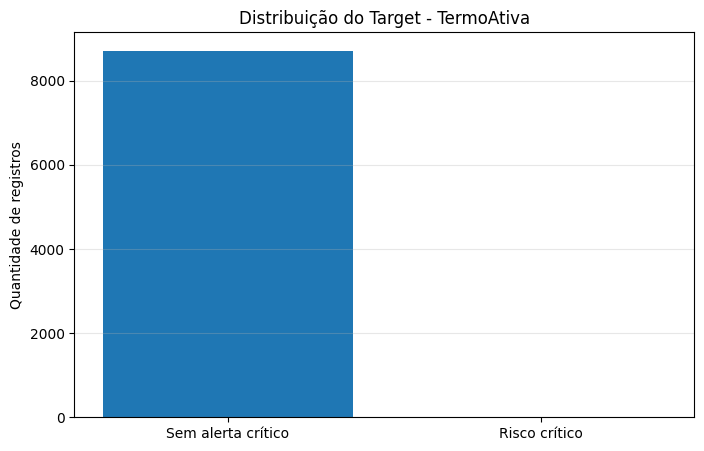

In [10]:

# ===========================================
# TERMOATIVA - TARGET DE RISCO AMBIENTAL
# ===========================================

# Limite inicial: categoria Danger do NWS
LIMIAR_CRITICO_F = 103.0

LIMIAR_CRITICO_C = (
    (LIMIAR_CRITICO_F - 32) * 5 / 9
)

# Criação do target binário
df_modelo["nivel_alerta_ambiental"] = (
    df_modelo["indice_calor_celsius"]
    >= LIMIAR_CRITICO_C
).astype(int)

# Quantidade de cada classe
contagem = (
    df_modelo["nivel_alerta_ambiental"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

print("=== DISTRIBUIÇÃO DAS CLASSES ===")

print("Classe 0 - Sem alerta crítico:", contagem[0])
print("Classe 1 - Risco crítico:", contagem[1])

print("\nPercentual por classe:")
print((contagem / len(df_modelo) * 100).round(2))

print("\nMaior índice de calor registrado:")
print(
    round(df_modelo["indice_calor_celsius"].max(), 2),
    "°C"
)

# Visualização das classes
plt.figure(figsize=(8, 5))

plt.bar(
    ["Sem alerta crítico", "Risco crítico"],
    contagem.values
)

plt.title("Distribuição do Target - TermoAtiva")
plt.ylabel("Quantidade de registros")
plt.grid(axis="y", alpha=0.3)

plt.show()


=== CATEGORIAS NOAA - MIRANTE 2025 ===


,Registros
categoria_noaa,
Abaixo de Caution,7734
Caution,937
Extreme Caution,42
Danger,0
Extreme Danger,0


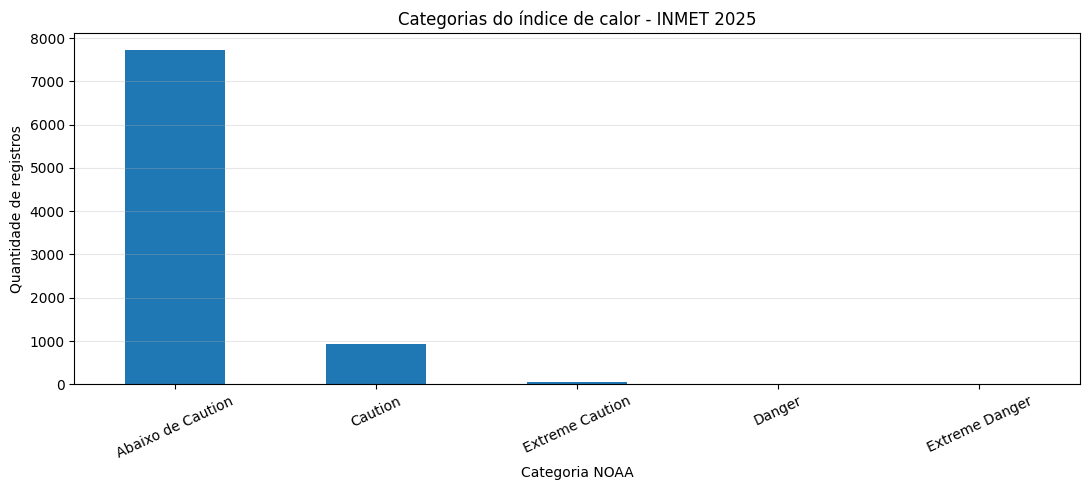

In [11]:

# ===========================================
# TERMOATIVA - CATEGORIAS DO HEAT INDEX
# ===========================================

# Limites da NOAA em Fahrenheit
limiares_f = [80, 90, 103, 125]

# Conversão para Celsius
limiares_c = [
    (valor - 32) * 5 / 9
    for valor in limiares_f
]

# Categorias oficiais do Heat Index
df_modelo["categoria_noaa"] = pd.cut(
    df_modelo["indice_calor_celsius"],
    bins=[-np.inf, *limiares_c, np.inf],
    labels=[
        "Abaixo de Caution",
        "Caution",
        "Extreme Caution",
        "Danger",
        "Extreme Danger"
    ],
    right=False
)

# Contagem das categorias
categorias = (
    df_modelo["categoria_noaa"]
    .value_counts(sort=False)
)

print("=== CATEGORIAS NOAA - MIRANTE 2025 ===")
display(categorias.to_frame("Registros"))

plt.figure(figsize=(11, 5))
categorias.plot(kind="bar")

plt.title("Categorias do índice de calor - INMET 2025")
plt.xlabel("Categoria NOAA")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

# ===========================================
# TERMOATIVA - EXPLORAÇÃO DE ESTAÇÕES DE SP
# ===========================================

# Seleciona os arquivos do estado de São Paulo
arquivos_sp = [
    nome for nome in arquivos_csv
    if "_SP_" in normalizar(Path(nome).name)
]

print("Estações de SP encontradas:", len(arquivos_sp))

# Seleciona apenas as colunas necessárias
def coluna_necessaria(nome):
    nome = normalizar(nome)

    return (
        ("TEMPERATURA DO AR" in nome
         and "BULBO SECO" in nome
         and "HORARIA" in nome)
        or
        ("UMIDADE RELATIVA DO AR" in nome
         and "HORARIA" in nome)
    )

def para_numero(serie):
    return pd.to_numeric(
        serie.str.replace(",", ".", regex=False),
        errors="coerce"
    ).replace(-9999, np.nan)

resultados_sp = []
erros_leitura = []

for caminho in arquivos_sp:

    try:
        with pacote.open(caminho) as arquivo:
            dados = pd.read_csv(
                arquivo,
                sep=";",
                encoding="latin1",
                skiprows=8,
                dtype=str,
                usecols=coluna_necessaria
            )

        # Identifica temperatura e umidade
        coluna_t = next(
            c for c in dados.columns
            if "TEMPERATURA DO AR" in normalizar(c)
        )

        coluna_u = next(
            c for c in dados.columns
            if "UMIDADE RELATIVA DO AR" in normalizar(c)
        )

        temperatura = para_numero(dados[coluna_t])
        umidade = para_numero(dados[coluna_u])

        # Mantém apenas medições válidas
        validos = (
            temperatura.between(-20, 55)
            & umidade.between(0, 100)
        )

        temperatura = temperatura[validos]
        umidade = umidade[validos]

        if len(temperatura) == 0:
            continue

        # Reutiliza a função NOAA da célula 10
        indices = np.array([
            calcular_indice_calor(t, u)
            for t, u in zip(temperatura, umidade)
        ])

        # Extrai identificador e cidade do arquivo
        partes = Path(caminho).name.split("_")
        codigo = partes[3]
        cidade = partes[4]

        criticos = int(
            (indices >= LIMIAR_CRITICO_C).sum()
        )

        resultados_sp.append({
            "estacao": codigo,
            "cidade": cidade,
            "registros_validos": len(indices),
            "criticos": criticos,
            "maior_indice_c": round(
                float(indices.max()), 2
            )
        })

    except Exception as erro:
        erros_leitura.append(
            (Path(caminho).name, str(erro))
        )

# Organiza os resultados
resumo_sp = pd.DataFrame(resultados_sp)

if resumo_sp.empty:
    raise RuntimeError(
        "Nenhuma estação paulista foi processada."
    )

resumo_sp = resumo_sp.sort_values(
    "criticos",
    ascending=False
).reset_index(drop=True)

print("\n=== RESULTADOS DAS ESTAÇÕES DE SP ===")

display(resumo_sp.head(20))

print("\nTotal de registros críticos:",
      resumo_sp["criticos"].sum())

print("Estações com pelo menos um registro crítico:",
      (resumo_sp["criticos"] > 0).sum())

print("Estações com erro de leitura:",
      len(erros_leitura))

if erros_leitura:
    print("Exemplos de erros:", erros_leitura[:5])


Estações de SP encontradas: 40

=== RESULTADOS DAS ESTAÇÕES DE SP ===


,estacao,cidade,registros_validos,criticos,maior_indice_c
0,A712,IGUAPE,6251,50,47.13
1,A764,BEBEDOURO,8345,29,43.00
2,A736,ARIRANHA,8358,17,43.79
3,A765,BERTIOGA,7897,16,46.92
4,A766,REGISTRO,461,8,43.02
5,A762,DRACENA,6246,4,40.68
6,A726,PIRACICABA,5929,4,41.86
7,A718,RANCHARIA,8202,2,40.20
8,A734,VALPARAISO,8749,1,39.47
9,A716,OURINHOS,8677,1,39.65



Total de registros críticos: 132
Estações com pelo menos um registro crítico: 10
Estações com erro de leitura: 0


In [13]:

# ===========================================
# TERMOATIVA - DATASET UNIFICADO DE SAO PAULO
# ===========================================

bases_sp = []

for caminho in arquivos_sp:

    # Carrega somente as variaveis necessarias
    with pacote.open(caminho) as arquivo:
        dados = pd.read_csv(
            arquivo,
            sep=";",
            encoding="latin1",
            skiprows=8,
            dtype=str,
            usecols=lambda c: (
                normalizar(c).strip() in ["DATA", "HORA UTC"]
                or "TEMPERATURA DO AR - BULBO SECO" in normalizar(c)
                or "UMIDADE RELATIVA DO AR" in normalizar(c)
                or "RADIACAO GLOBAL" in normalizar(c)
            )
        )

    dados.columns = dados.columns.str.strip()

    def localizar(termos):
        for coluna in dados.columns:
            nome = normalizar(coluna)
            if all(termo in nome for termo in termos):
                return coluna
        return None

    c_data = localizar(["DATA"])
    c_hora = localizar(["HORA UTC"])
    c_temp = localizar(["TEMPERATURA DO AR", "BULBO SECO"])
    c_umidade = localizar(["UMIDADE RELATIVA DO AR"])
    c_radiacao = localizar(["RADIACAO GLOBAL"])

    if any(c is None for c in [
        c_data, c_hora, c_temp, c_umidade
    ]):
        continue

    # Converte as medidas meteorologicas
    temperatura = para_numero(dados[c_temp])
    umidade = para_numero(dados[c_umidade])

    if c_radiacao is not None:
        radiacao = para_numero(dados[c_radiacao])
    else:
        radiacao = pd.Series(
            np.nan, index=dados.index
        )

    # Construcao do horario UTC
    datas = pd.to_datetime(
        dados[c_data].str.strip(),
        format="%Y/%m/%d",
        errors="coerce"
    )

    horario = dados[c_hora].str.extract(
        r"(\d{2}):?(\d{2})"
    )

    horas = pd.to_numeric(
        horario[0], errors="coerce"
    )
    minutos = pd.to_numeric(
        horario[1], errors="coerce"
    )

    data_hora_utc = (
        datas
        + pd.to_timedelta(horas, unit="h")
        + pd.to_timedelta(minutos, unit="m")
    ).dt.tz_localize("UTC")

    # Verifica valores fisicamente plausiveis
    validos = (
        temperatura.between(-20, 55)
        & umidade.between(0, 100)
        & data_hora_utc.notna()
    )

    if validos.sum() == 0:
        continue

    # Identifica a estacao e a cidade
    partes = Path(caminho).name.split("_")
    codigo = partes[3]
    cidade = partes[4]

    # Cria a base individual da estacao
    base = pd.DataFrame({
        "estacao": codigo,
        "cidade": cidade,
        "data_hora_utc": data_hora_utc[validos],
        "temperatura_ar_celsius": temperatura[validos],
        "umidade_relativa_ar": umidade[validos],
        "radiacao_global_kj_m2": radiacao[validos]
    })

    # Converte para horario de Sao Paulo
    data_local = base["data_hora_utc"].dt.tz_convert(
        "America/Sao_Paulo"
    )

    base["hora_do_dia"] = (
        data_local.dt.hour.replace({0: 24})
    )

    # Calcula o indice de calor
    base["indice_calor_celsius"] = [
        calcular_indice_calor(t, u)
        for t, u in zip(
            base["temperatura_ar_celsius"],
            base["umidade_relativa_ar"]
        )
    ]

    # Cria o target com o mesmo criterio NOAA
    base["nivel_alerta_ambiental"] = (
        base["indice_calor_celsius"]
        >= LIMIAR_CRITICO_C
    ).astype(int)

    bases_sp.append(base)

# Junta as estacoes
df_sp = pd.concat(
    bases_sp, ignore_index=True
)

# Elimina eventuais registros duplicados
df_sp = df_sp.drop_duplicates(
    subset=["estacao", "data_hora_utc"]
)

# Organiza por tempo e estacao
df_sp = df_sp.sort_values(
    ["data_hora_utc", "estacao"]
).reset_index(drop=True)

print("=== DATASET UNIFICADO ===")
print("Total de registros:", len(df_sp))
print("Estacoes:", df_sp["estacao"].nunique())

print("\nDistribuicao do target:")
print(
    df_sp["nivel_alerta_ambiental"]
    .value_counts()
    .sort_index()
)

display(df_sp.head())


=== DATASET UNIFICADO ===
Total de registros: 292745
Estacoes: 40

Distribuicao do target:
nivel_alerta_ambiental
0    292613
1       132
Name: count, dtype: int64


,estacao,cidade,data_hora_utc,temperatura_ar_celsius,umidade_relativa_ar,radiacao_global_kj_m2,hora_do_dia,indice_calor_celsius,nivel_alerta_ambiental
0,A701,SAO PAULO - MIRANTE,2025-01-01 00:00:00+00:00,21.2,76.0,NaN,21,21.280000,0
1,A705,BAURU,2025-01-01 00:00:00+00:00,24.7,73.0,NaN,21,24.915833,0
2,A706,CAMPOS DO JORDAO,2025-01-01 00:00:00+00:00,15.6,88.0,NaN,21,15.556667,0
3,A707,PRESIDENTE PRUDENTE,2025-01-01 00:00:00+00:00,26.2,66.0,NaN,21,26.399444,0
4,A712,IGUAPE,2025-01-01 00:00:00+00:00,24.3,87.0,NaN,21,24.678611,0


=== DISTRIBUICAO GERAL ===
Classe 0: 292613
Classe 1: 132
Percentual de risco critico: 0.0451%

=== ESTACOES COM MAIS ALERTAS ===


,estacao,cidade,registros,alertas_criticos,maior_indice
6,A712,IGUAPE,6251,50,47.13
33,A764,BEBEDOURO,8345,29,43.00
19,A736,ARIRANHA,8358,17,43.79
34,A765,BERTIOGA,7897,16,46.92
35,A766,REGISTRO,461,8,43.02
31,A762,DRACENA,6246,4,40.68
13,A726,PIRACICABA,5929,4,41.86
11,A718,RANCHARIA,8202,2,40.20
17,A734,VALPARAISO,8749,1,39.47
10,A716,OURINHOS,8677,1,39.65



=== ALERTAS POR MES ===


,mes_utc,registros,criticos
0,1,22330,45
1,2,19817,50
2,3,21232,8
3,4,23775,4
4,5,27512,0
5,6,26143,0
6,7,26691,0
7,8,25904,0
8,9,24179,1
9,10,24058,0


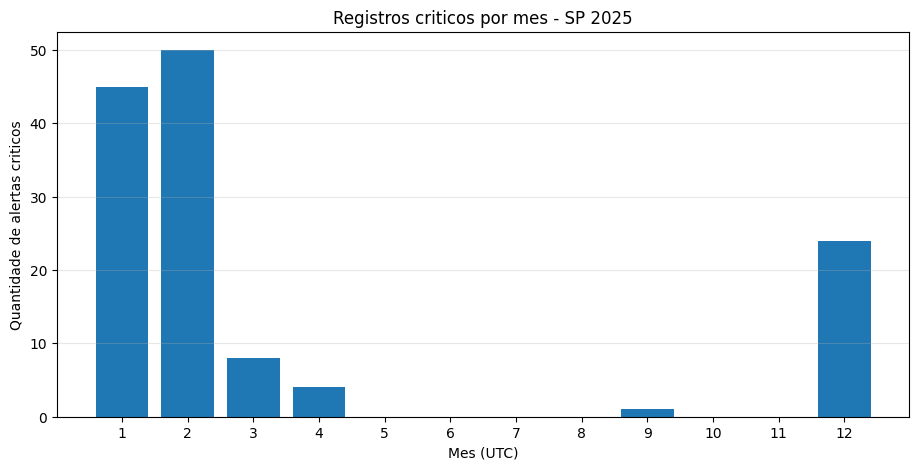


=== MAIORES INDICES DE CALOR ===


,cidade,data_hora_utc,temperatura_ar_celsius,umidade_relativa_ar,indice_calor_celsius,nivel_alerta_ambiental
33422,IGUAPE,2025-02-16 17:00:00+00:00,34.4,68.0,47.13,1
34235,BERTIOGA,2025-02-17 19:00:00+00:00,34.8,65.0,46.92,1
33453,IGUAPE,2025-02-16 18:00:00+00:00,33.6,69.0,44.96,1
30619,IGUAPE,2025-02-12 18:00:00+00:00,34.1,65.0,44.69,1
33391,IGUAPE,2025-02-16 16:00:00+00:00,33.3,69.0,43.99,1
52538,ARIRANHA,2025-03-15 19:00:00+00:00,35.9,52.0,43.79,1
25599,IGUAPE,2025-02-05 17:00:00+00:00,34.7,58.0,43.26,1
292475,REGISTRO,2025-12-31 16:00:00+00:00,34.3,60.0,43.02,1
16545,BEBEDOURO,2025-01-23 19:00:00+00:00,35.6,52.0,43.00,1
34120,IGUAPE,2025-02-17 16:00:00+00:00,38.2,38.0,42.97,1


In [14]:

# ===========================================
# TERMOATIVA - ANALISE DO DATASET CONSOLIDADO
# ===========================================

# Distribuicao geral das classes
contagem = (
    df_sp["nivel_alerta_ambiental"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

print("=== DISTRIBUICAO GERAL ===")
print("Classe 0:", contagem[0])
print("Classe 1:", contagem[1])

percentual = contagem[1] / len(df_sp) * 100

print(f"Percentual de risco critico: {percentual:.4f}%")

# Alertas por estacao
resumo_estacoes = (
    df_sp.groupby(["estacao", "cidade"])
    .agg(
        registros=("nivel_alerta_ambiental", "size"),
        alertas_criticos=("nivel_alerta_ambiental", "sum"),
        maior_indice=("indice_calor_celsius", "max")
    )
    .reset_index()
    .sort_values("alertas_criticos", ascending=False)
)

print("\n=== ESTACOES COM MAIS ALERTAS ===")
display(resumo_estacoes.head(15).round(2))

# Distribuicao mensal no horario UTC
df_sp["mes_utc"] = df_sp["data_hora_utc"].dt.month

resumo_mensal = (
    df_sp.groupby("mes_utc")
    .agg(
        registros=("nivel_alerta_ambiental", "size"),
        criticos=("nivel_alerta_ambiental", "sum")
    )
    .reset_index()
)

print("\n=== ALERTAS POR MES ===")
display(resumo_mensal)

# Grafico de alertas por mes
plt.figure(figsize=(11, 5))

plt.bar(
    resumo_mensal["mes_utc"],
    resumo_mensal["criticos"]
)

plt.title("Registros criticos por mes - SP 2025")
plt.xlabel("Mes (UTC)")
plt.ylabel("Quantidade de alertas criticos")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)

plt.show()

# Inspeciona os valores mais extremos
print("\n=== MAIORES INDICES DE CALOR ===")

display(
    df_sp.sort_values(
        "indice_calor_celsius",
        ascending=False
    )[[
        "cidade",
        "data_hora_utc",
        "temperatura_ar_celsius",
        "umidade_relativa_ar",
        "indice_calor_celsius",
        "nivel_alerta_ambiental"
    ]].head(15).round(2)
)


In [15]:

# ===========================================
# TERMOATIVA - ANALISE DOS DIAS CRITICOS
# ===========================================

# Cria identificador de dia em UTC
df_sp["dia_utc"] = (
    df_sp["data_hora_utc"].dt.floor("D")
)

# Identifica dias que tiveram alertas
resumo_dias = (
    df_sp.groupby("dia_utc")
    .agg(
        registros=("nivel_alerta_ambiental", "size"),
        alertas=("nivel_alerta_ambiental", "sum")
    )
    .reset_index()
)

# 1 = dia com pelo menos um alerta
resumo_dias["dia_critico"] = (
    resumo_dias["alertas"] > 0
).astype(int)

print("=== ANALISE DOS DIAS ===")

print("Total de dias:", len(resumo_dias))

print(
    "Dias com alertas:",
    resumo_dias["dia_critico"].sum()
)

print(
    "Dias sem alertas:",
    (resumo_dias["dia_critico"] == 0).sum()
)

print("\nDias com maior quantidade de alertas:")

display(
    resumo_dias.sort_values(
        "alertas", ascending=False
    ).head(15)
)

# Verifica a ausencia de radiacao por classe
print("\n=== RADIACAO POR CLASSE ===")

radiacao_classe = (
    df_sp.groupby("nivel_alerta_ambiental")[
        "radiacao_global_kj_m2"
    ]
    .agg(["size", "count"])
)

radiacao_classe["percentual_ausente"] = (
    (radiacao_classe["size"] - radiacao_classe["count"])
    / radiacao_classe["size"] * 100
).round(2)

display(radiacao_classe)


=== ANALISE DOS DIAS ===
Total de dias: 365
Dias com alertas: 45
Dias sem alertas: 320

Dias com maior quantidade de alertas:


,dia_utc,registros,alertas,dia_critico
47,2025-02-17 00:00:00+00:00,727,12,1
19,2025-01-20 00:00:00+00:00,705,11,1
51,2025-02-21 00:00:00+00:00,718,9,1
21,2025-01-22 00:00:00+00:00,718,6,1
46,2025-02-16 00:00:00+00:00,717,6,1
73,2025-03-15 00:00:00+00:00,692,5,1
359,2025-12-26 00:00:00+00:00,912,5,1
361,2025-12-28 00:00:00+00:00,907,5,1
20,2025-01-21 00:00:00+00:00,712,5,1
364,2025-12-31 00:00:00+00:00,884,4,1



=== RADIACAO POR CLASSE ===


,size,count,percentual_ausente
nivel_alerta_ambiental,,,
0,292613,162119,44.6
1,132,106,19.7


In [16]:

# ===========================================
# TERMOATIVA - SEPARACAO DOS DADOS
# ===========================================

from sklearn.model_selection import train_test_split

# Verifica se temos dias criticos suficientes
qtd_dias_criticos = resumo_dias["dia_critico"].sum()

if qtd_dias_criticos < 10:
    raise ValueError(
        "Poucos dias criticos para esta divisao. "
        "Precisamos ampliar a base."
    )

# Primeira divisao: 60% treino e 40% restantes
dias_treino, dias_restantes = train_test_split(
    resumo_dias,
    test_size=0.40,
    random_state=42,
    stratify=resumo_dias["dia_critico"]
)

# Segunda divisao: 20% validacao e 20% teste
dias_validacao, dias_teste = train_test_split(
    dias_restantes,
    test_size=0.50,
    random_state=42,
    stratify=dias_restantes["dia_critico"]
)

# Separa os registros por dia
df_treino = df_sp[
    df_sp["dia_utc"].isin(dias_treino["dia_utc"])
].copy()

df_validacao = df_sp[
    df_sp["dia_utc"].isin(dias_validacao["dia_utc"])
].copy()

df_teste = df_sp[
    df_sp["dia_utc"].isin(dias_teste["dia_utc"])
].copy()

# Verifica a distribuicao das classes
def conferir_conjunto(nome, dados):
    positivos = int(
        dados["nivel_alerta_ambiental"].sum()
    )

    print(f"\n{nome}")
    print("Registros:", len(dados))
    print("Classe 0:", len(dados) - positivos)
    print("Classe 1:", positivos)

conferir_conjunto("TREINAMENTO", df_treino)
conferir_conjunto("VALIDACAO", df_validacao)
conferir_conjunto("TESTE", df_teste)

# Confirma que nenhum dia aparece em dois conjuntos
assert set(dias_treino["dia_utc"]).isdisjoint(
    set(dias_validacao["dia_utc"])
)

assert set(dias_treino["dia_utc"]).isdisjoint(
    set(dias_teste["dia_utc"])
)

assert set(dias_validacao["dia_utc"]).isdisjoint(
    set(dias_teste["dia_utc"])
)

print("\nSeparacao por dias verificada!")



TREINAMENTO
Registros: 176362
Classe 0: 176285
Classe 1: 77

VALIDACAO
Registros: 58076
Classe 0: 58056
Classe 1: 20

TESTE
Registros: 58307
Classe 0: 58272
Classe 1: 35

Separacao por dias verificada!


In [17]:

# ===========================================
# TERMOATIVA - PREPARACAO DAS FEATURES
# ===========================================

# Variaveis de entrada do modelo
features = [
    "temperatura_ar_celsius",
    "umidade_relativa_ar",
    "hora_do_dia"
]

# Variavel que desejamos prever
target = "nivel_alerta_ambiental"

# Conjunto de treinamento
X_treino = df_treino[features].copy()
y_treino = df_treino[target].astype(int)

# Conjunto de validacao
X_validacao = df_validacao[features].copy()
y_validacao = df_validacao[target].astype(int)

# Conjunto de teste (reservado para o final)
X_teste = df_teste[features].copy()
y_teste = df_teste[target].astype(int)

# Verificacao de valores ausentes
print("=== VERIFICACAO DAS FEATURES ===")

print("\nVariaveis utilizadas:")
print(features)

print("\nValores ausentes no treinamento:")
print(X_treino.isna().sum())

print("\nDistribuicao do target no treinamento:")
print(y_treino.value_counts())

# Garante que nao existem valores ausentes
assert X_treino.notna().all().all()
assert X_validacao.notna().all().all()
assert X_teste.notna().all().all()

print("\nDados preparados com sucesso!")


=== VERIFICACAO DAS FEATURES ===

Variaveis utilizadas:
['temperatura_ar_celsius', 'umidade_relativa_ar', 'hora_do_dia']

Valores ausentes no treinamento:
temperatura_ar_celsius    0
umidade_relativa_ar       0
hora_do_dia               0
dtype: int64

Distribuicao do target no treinamento:
nivel_alerta_ambiental
0    176285
1        77
Name: count, dtype: int64

Dados preparados com sucesso!


In [18]:

# ===========================================
# TERMOATIVA - TREINAMENTO DO MODELO
# ===========================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Cria o pipeline de Machine Learning
modelo = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regressao_logistica",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Treinamento do modelo
print("Iniciando treinamento...")

modelo.fit(X_treino, y_treino)

print("Modelo treinado com sucesso!")

# Exibe os parametros utilizados
print("\n=== CONFIGURACAO DO MODELO ===")

print(modelo)

# Coeficientes da regressao logistica
coeficientes = (
    modelo.named_steps["regressao_logistica"]
    .coef_[0]
)

tabela_coeficientes = pd.DataFrame({
    "Variavel": features,
    "Coeficiente": coeficientes
})

print("\nCoeficientes do modelo:")
display(tabela_coeficientes)


Iniciando treinamento...
Modelo treinado com sucesso!

=== CONFIGURACAO DO MODELO ===
Pipeline(steps=[('scaler', StandardScaler()),
                ('regressao_logistica',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

Coeficientes do modelo:


,Variavel,Coeficiente
0,temperatura_ar_celsius,27.283665
1,umidade_relativa_ar,14.273476
2,hora_do_dia,-0.936657


=== METRICAS DE VALIDACAO ===
Acuracia: 0.9977
Precisao: 0.1316
Recall: 1.0000
F1-Score: 0.2326

=== MATRIZ DE CONFUSAO ===
Verdadeiros negativos: 57924
Falsos positivos: 132
Falsos negativos: 0
Verdadeiros positivos: 20


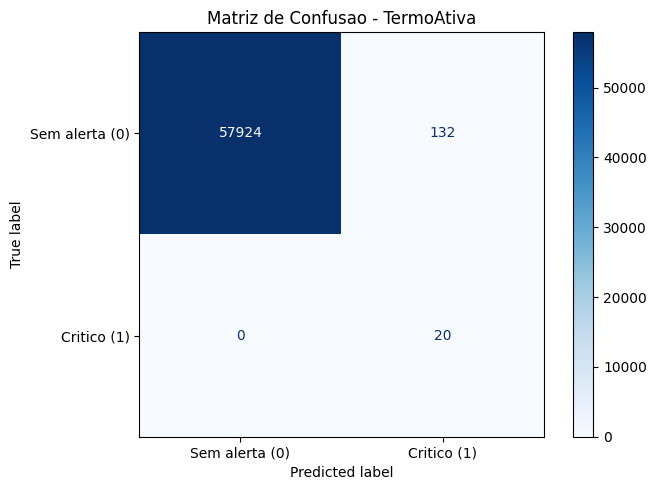


=== RELATORIO DE CLASSIFICACAO ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     58056
           1       0.13      1.00      0.23        20

    accuracy                           1.00     58076
   macro avg       0.57      1.00      0.62     58076
weighted avg       1.00      1.00      1.00     58076



In [19]:

# ===========================================
# TERMOATIVA - AVALIACAO INICIAL DO MODELO
# ===========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Previsoes no conjunto de validacao
y_pred = modelo.predict(X_validacao)

# Calculo das metricas
acuracia = accuracy_score(y_validacao, y_pred)

precisao = precision_score(
    y_validacao, y_pred, zero_division=0
)

recall = recall_score(
    y_validacao, y_pred, zero_division=0
)

f1 = f1_score(
    y_validacao, y_pred, zero_division=0
)

print("=== METRICAS DE VALIDACAO ===")

print(f"Acuracia: {acuracia:.4f}")
print(f"Precisao: {precisao:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Matriz de confusao
matriz = confusion_matrix(
    y_validacao,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz.ravel()

print("\n=== MATRIZ DE CONFUSAO ===")

print("Verdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

# Exibicao grafica
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        "Sem alerta (0)",
        "Critico (1)"
    ]
).plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matriz de Confusao - TermoAtiva")
plt.tight_layout()
plt.show()

# Relatorio detalhado
print("\n=== RELATORIO DE CLASSIFICACAO ===")

print(classification_report(
    y_validacao,
    y_pred,
    labels=[0, 1],
    zero_division=0
))


=== DISTRIBUICAO DOS SCORES ===


,count,mean,std,min,25%,50%,75%,max
classe_real,,,,,,,,
0,58056.0,0.0028,0.0407,0.000,0.0000,0.000,0.0000,0.9975
1,20.0,0.9975,0.0023,0.992,0.9957,0.998,0.9997,1.0000


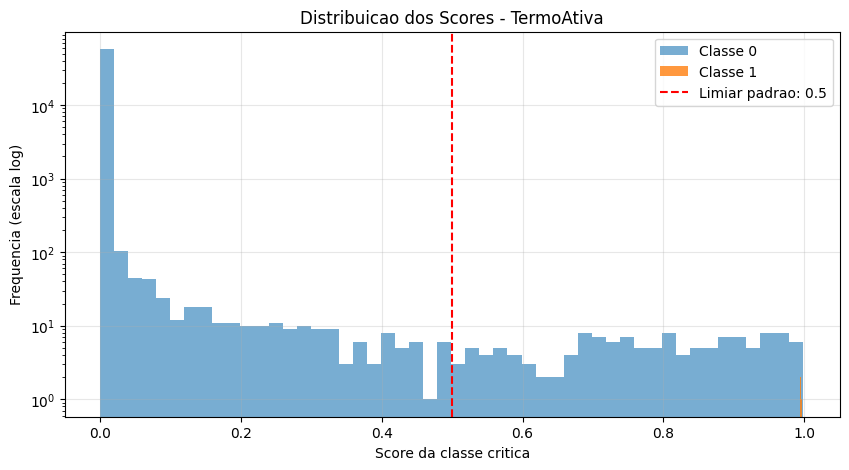

In [20]:

# ===========================================
# TERMOATIVA - PROBABILIDADES DO MODELO
# ===========================================

# Score associado a classe 1
prob_validacao = modelo.predict_proba(
    X_validacao
)[:, 1]

# Cria tabela para analise
df_probabilidades = pd.DataFrame({
    "classe_real": y_validacao.to_numpy(),
    "score_critico": prob_validacao
})

print("=== DISTRIBUICAO DOS SCORES ===")

display(
    df_probabilidades.groupby("classe_real")[
        "score_critico"
    ].describe().round(4)
)

# Histograma dos scores
plt.figure(figsize=(10, 5))

plt.hist(
    df_probabilidades.loc[
        df_probabilidades["classe_real"] == 0,
        "score_critico"
    ],
    bins=50,
    alpha=0.6,
    label="Classe 0"
)

plt.hist(
    df_probabilidades.loc[
        df_probabilidades["classe_real"] == 1,
        "score_critico"
    ],
    bins=30,
    alpha=0.8,
    label="Classe 1"
)

plt.axvline(
    0.5,
    linestyle="--",
    color="red",
    label="Limiar padrao: 0.5"
)

plt.yscale("log")
plt.title("Distribuicao dos Scores - TermoAtiva")
plt.xlabel("Score da classe critica")
plt.ylabel("Frequencia (escala log)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


=== LIMIAR SELECIONADO ===
Limiar: 0.9891
Precisao: 0.8333
Recall: 1.0000
Falsos positivos: 4
Falsos negativos: 0

=== MELHORES CANDIDATOS ===


,limiar,precisao,recall,f1,falsos_positivos,falsos_negativos
198,0.9891,0.8333,1.0,0.9091,4,0
196,0.9791,0.7692,1.0,0.8696,6,0
197,0.9841,0.7692,1.0,0.8696,6,0
195,0.9742,0.7692,1.0,0.8696,6,0
194,0.9692,0.6667,1.0,0.8000,10,0
193,0.9642,0.6452,1.0,0.7843,11,0
192,0.9592,0.5882,1.0,0.7407,14,0
191,0.9543,0.5556,1.0,0.7143,16,0
190,0.9493,0.5263,1.0,0.6897,18,0
189,0.9443,0.5000,1.0,0.6667,20,0


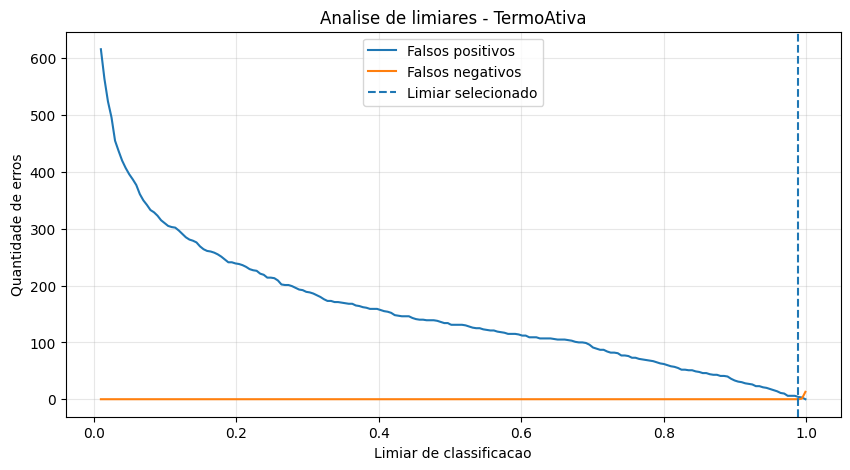

In [21]:

# ===========================================
# TERMOATIVA - AJUSTE DO LIMIAR
# ===========================================

# Diferentes limiares de classificacao
limiares = np.unique(
    np.r_[
        np.linspace(0.01, 0.999, 200),
        0.5
    ]
)

resultados = []

for limiar in limiares:

    previsao = (
        prob_validacao >= limiar
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validacao,
        previsao,
        labels=[0, 1]
    ).ravel()

    resultados.append({
        "limiar": limiar,
        "precisao": precision_score(
            y_validacao, previsao,
            zero_division=0
        ),
        "recall": recall_score(
            y_validacao, previsao,
            zero_division=0
        ),
        "f1": f1_score(
            y_validacao, previsao,
            zero_division=0
        ),
        "falsos_positivos": fp,
        "falsos_negativos": fn
    })

df_limiares = pd.DataFrame(resultados)

# Mantem limiares com Recall de 100%
candidatos = df_limiares[
    df_limiares["recall"] == 1.0
].copy()

# Seleciona o que apresenta menos falsos positivos
melhor = candidatos.sort_values(
    ["falsos_positivos", "limiar"],
    ascending=[True, False]
).iloc[0]

limiar_escolhido = float(melhor["limiar"])

print("=== LIMIAR SELECIONADO ===")
print(f"Limiar: {limiar_escolhido:.4f}")
print(f"Precisao: {melhor['precisao']:.4f}")
print(f"Recall: {melhor['recall']:.4f}")
print(
    "Falsos positivos:",
    int(melhor["falsos_positivos"])
)
print(
    "Falsos negativos:",
    int(melhor["falsos_negativos"])
)

print("\n=== MELHORES CANDIDATOS ===")
display(
    candidatos.sort_values(
        "falsos_positivos"
    ).head(10).round(4)
)

# Visualizacao dos erros
plt.figure(figsize=(10, 5))

plt.plot(
    df_limiares["limiar"],
    df_limiares["falsos_positivos"],
    label="Falsos positivos"
)

plt.plot(
    df_limiares["limiar"],
    df_limiares["falsos_negativos"],
    label="Falsos negativos"
)

plt.axvline(
    limiar_escolhido,
    linestyle="--",
    label="Limiar selecionado"
)

plt.xlabel("Limiar de classificacao")
plt.ylabel("Quantidade de erros")
plt.title("Analise de limiares - TermoAtiva")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


=== RESULTADOS AJUSTADOS ===
Acuracia: 0.9999
Precisao: 0.8333
Recall: 1.0
F1-score: 0.9091

Falsos positivos: 4
Falsos negativos: 0
Verdadeiros positivos: 20


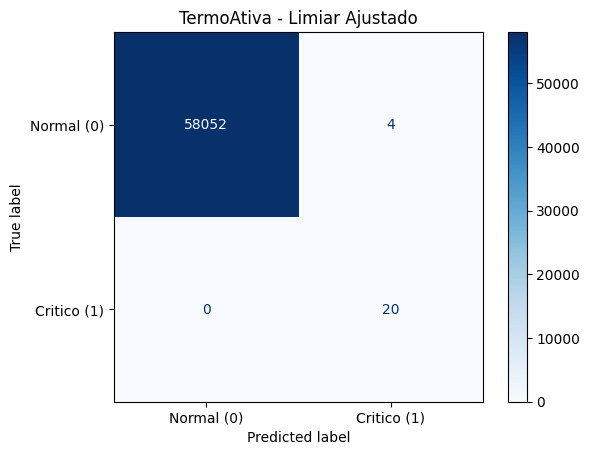

In [22]:

# ===========================================
# TERMOATIVA - AVALIACAO DO LIMIAR AJUSTADO
# ===========================================

# Previsao com limiar selecionado
y_pred_ajustado = (
    prob_validacao >= limiar_escolhido
).astype(int)

# Metricas do modelo ajustado
print("=== RESULTADOS AJUSTADOS ===")

print(
    "Acuracia:",
    round(accuracy_score(
        y_validacao, y_pred_ajustado
    ), 4)
)

print(
    "Precisao:",
    round(precision_score(
        y_validacao, y_pred_ajustado,
        zero_division=0
    ), 4)
)

print(
    "Recall:",
    round(recall_score(
        y_validacao, y_pred_ajustado,
        zero_division=0
    ), 4)
)

print(
    "F1-score:",
    round(f1_score(
        y_validacao, y_pred_ajustado,
        zero_division=0
    ), 4)
)

# Nova matriz de confusao
matriz_ajustada = confusion_matrix(
    y_validacao,
    y_pred_ajustado,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_ajustada.ravel()

print("\nFalsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_ajustada,
    display_labels=[
        "Normal (0)",
        "Critico (1)"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title("TermoAtiva - Limiar Ajustado")
plt.show()


In [23]:

# ===========================================
# TERMOATIVA - FEATURES COM RADIACAO SOLAR
# ===========================================

# Quatro variaveis de entrada
features_radiacao = [
    "temperatura_ar_celsius",
    "umidade_relativa_ar",
    "hora_do_dia",
    "radiacao_global_kj_m2"
]

# Utilizamos exatamente os mesmos conjuntos
# definidos anteriormente
X_treino_rad = df_treino[features_radiacao].copy()
X_validacao_rad = df_validacao[features_radiacao].copy()

print("=== VARIAVEIS DO NOVO MODELO ===")
print(features_radiacao)

print("\nValores ausentes no treinamento:")
print(X_treino_rad.isna().sum())

print("\nValores ausentes na validacao:")
print(X_validacao_rad.isna().sum())

print("\nDimensoes dos conjuntos:")
print("Treinamento:", X_treino_rad.shape)
print("Validacao:", X_validacao_rad.shape)

# Confere que os conjuntos possuem
# a mesma quantidade de registros
assert len(X_treino_rad) == len(X_treino)
assert len(X_validacao_rad) == len(X_validacao)

print("\nConjuntos preparados com sucesso!")


=== VARIAVEIS DO NOVO MODELO ===
['temperatura_ar_celsius', 'umidade_relativa_ar', 'hora_do_dia', 'radiacao_global_kj_m2']

Valores ausentes no treinamento:
temperatura_ar_celsius        0
umidade_relativa_ar           0
hora_do_dia                   0
radiacao_global_kj_m2     79379
dtype: int64

Valores ausentes na validacao:
temperatura_ar_celsius        0
umidade_relativa_ar           0
hora_do_dia                   0
radiacao_global_kj_m2     25827
dtype: int64

Dimensoes dos conjuntos:
Treinamento: (176362, 4)
Validacao: (58076, 4)

Conjuntos preparados com sucesso!


In [24]:

# ===========================================
# TERMOATIVA - MODELO COM RADIACAO SOLAR
# ===========================================

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline de classificacao
modelo_radiacao = Pipeline([
    (
        "imputador",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regressao_logistica",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("Treinando modelo com radiação solar...")

# Treina somente com os dados de treinamento
modelo_radiacao.fit(
    X_treino_rad,
    y_treino
)

print("\nTreinamento concluido!")

print("\n=== PIPELINE ===")
print(modelo_radiacao)

print("\nMedianas usadas para imputacao:")
print(
    modelo_radiacao.named_steps[
        "imputador"
    ].statistics_
)


Treinando modelo com radiação solar...

Treinamento concluido!

=== PIPELINE ===
Pipeline(steps=[('imputador',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('scaler', StandardScaler()),
                ('regressao_logistica',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

Medianas usadas para imputacao:
[ 21.4  74.   13.  971.3]


=== COMPARACAO DOS MODELOS ===
Limiar utilizado: 0.5


,Modelo,Acuracia,Precisao,Recall,F1-score,Falsos positivos,Falsos negativos
0,Sem radiacao,0.9977,0.1316,1.0,0.2326,132,0
1,Com radiacao,0.9977,0.1325,1.0,0.2339,131,0


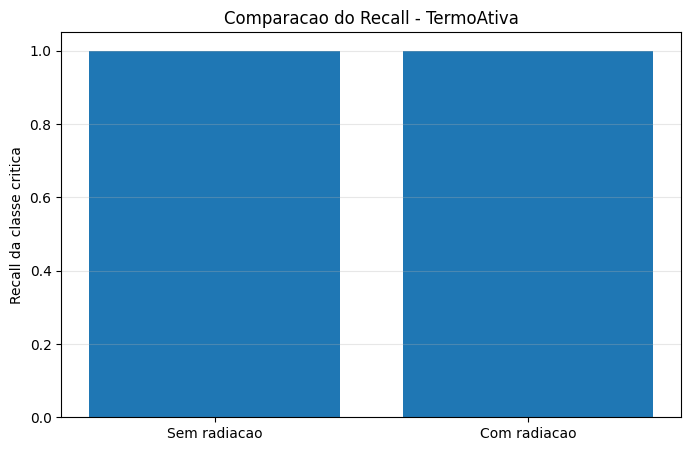

In [25]:

# ===========================================
# TERMOATIVA - COMPARACAO DE MODELOS
# ===========================================

def avaliar_modelo(nome, modelo_ml, X):

    # Scores da classe critica
    scores = modelo_ml.predict_proba(X)[:, 1]

    # Classificacao com limiar padrao
    previsoes = (scores >= 0.5).astype(int)

    # Matriz de confusao
    tn, fp, fn, tp = confusion_matrix(
        y_validacao,
        previsoes,
        labels=[0, 1]
    ).ravel()

    return {
        "Modelo": nome,
        "Acuracia": accuracy_score(
            y_validacao, previsoes
        ),
        "Precisao": precision_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "Falsos positivos": fp,
        "Falsos negativos": fn
    }


# Modelo original com tres variaveis
resultado_original = avaliar_modelo(
    "Sem radiacao",
    modelo,
    X_validacao
)

# Modelo novo com quatro variaveis
resultado_radiacao = avaliar_modelo(
    "Com radiacao",
    modelo_radiacao,
    X_validacao_rad
)

# Tabela comparativa
comparacao = pd.DataFrame([
    resultado_original,
    resultado_radiacao
])

print("=== COMPARACAO DOS MODELOS ===")
print("Limiar utilizado: 0.5")

display(comparacao.round(4))

# Visualizacao do Recall
plt.figure(figsize=(8, 5))

plt.bar(
    comparacao["Modelo"],
    comparacao["Recall"]
)

plt.title("Comparacao do Recall - TermoAtiva")
plt.ylabel("Recall da classe critica")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [26]:

# ===========================================
# TERMOATIVA - COMPARACAO DE LIMIARES
# ===========================================

def comparar_limiar(nome, modelo_ml, X):

    # Calcula os scores da classe critica
    scores = modelo_ml.predict_proba(X)[:, 1]

    # Identifica os registros realmente criticos
    y_real = y_validacao.to_numpy()
    scores_criticos = scores[y_real == 1]

    if len(scores_criticos) == 0:
        raise ValueError("Nao existem exemplos criticos.")

    # Maior limiar que identifica todos os
    # registros criticos da validacao
    limiar = float(scores_criticos.min())

    # Realiza as previsoes com o novo limiar
    previsoes = (scores >= limiar).astype(int)

    # Matriz de confusao
    tn, fp, fn, tp = confusion_matrix(
        y_real,
        previsoes,
        labels=[0, 1]
    ).ravel()

    return {
        "Modelo": nome,
        "Limiar": limiar,
        "Acuracia": accuracy_score(
            y_real, previsoes
        ),
        "Precisao": precision_score(
            y_real, previsoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_real, previsoes,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_real, previsoes,
            zero_division=0
        ),
        "FP": fp,
        "FN": fn,
        "VP": tp
    }


# Avalia os dois modelos
resultado_sem_rad = comparar_limiar(
    "Sem radiacao",
    modelo,
    X_validacao
)

resultado_com_rad = comparar_limiar(
    "Com radiacao",
    modelo_radiacao,
    X_validacao_rad
)

# Tabela de comparacao
comparacao_ajustada = pd.DataFrame([
    resultado_sem_rad,
    resultado_com_rad
])

print("=== COMPARACAO COM LIMIARES AJUSTADOS ===")

display(comparacao_ajustada.round(4))


=== COMPARACAO COM LIMIARES AJUSTADOS ===


,Modelo,Limiar,Acuracia,Precisao,Recall,F1-score,FP,FN,VP
0,Sem radiacao,0.992,0.9999,0.8333,1.0,0.9091,4,0,20
1,Com radiacao,0.994,0.9999,0.8333,1.0,0.9091,4,0,20


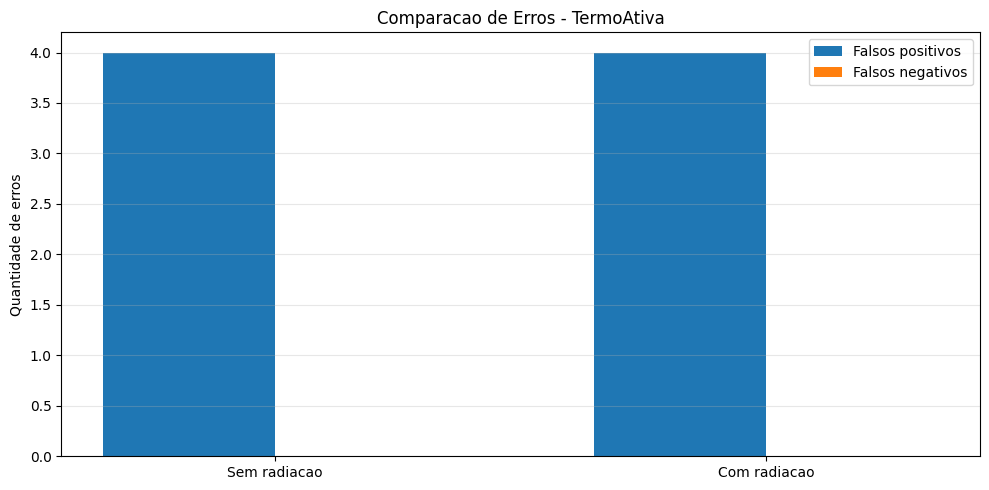

=== ANALISE COMPARATIVA ===
FP sem radiacao: 4
FP com radiacao: 4

Diferenca de falsos positivos: 0
Os modelos tiveram o mesmo numero de FP.

Recall sem radiacao: 1.0
Recall com radiacao: 1.0


In [27]:

# ===========================================
# TERMOATIVA - GRAFICO COMPARATIVO
# ===========================================

# Organiza os resultados
nomes = comparacao_ajustada["Modelo"]
fp = comparacao_ajustada["FP"]
fn = comparacao_ajustada["FN"]

posicoes = np.arange(len(nomes))
largura = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    posicoes - largura / 2,
    fp,
    largura,
    label="Falsos positivos"
)

plt.bar(
    posicoes + largura / 2,
    fn,
    largura,
    label="Falsos negativos"
)

plt.xticks(posicoes, nomes)
plt.ylabel("Quantidade de erros")
plt.title("Comparacao de Erros - TermoAtiva")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Comparacao das diferencas
fp_sem = int(resultado_sem_rad["FP"])
fp_com = int(resultado_com_rad["FP"])

print("=== ANALISE COMPARATIVA ===")

print("FP sem radiacao:", fp_sem)
print("FP com radiacao:", fp_com)

print("\nDiferenca de falsos positivos:",
      fp_sem - fp_com)

if fp_com < fp_sem:
    print("Modelo com radiacao teve menos FP.")
elif fp_com > fp_sem:
    print("Modelo sem radiacao teve menos FP.")
else:
    print("Os modelos tiveram o mesmo numero de FP.")

print("\nRecall sem radiacao:",
      resultado_sem_rad["Recall"])

print("Recall com radiacao:",
      resultado_com_rad["Recall"])


In [28]:

# ===========================================
# TERMOATIVA - DEFINICAO DO MODELO FINAL
# ===========================================

# Modelo selecionado na etapa anterior
modelo_final = modelo

# Features utilizadas
features_finais = [
    "temperatura_ar_celsius",
    "umidade_relativa_ar",
    "hora_do_dia"
]

# Limiar definido usando apenas a validacao
limiar_final = float(
    resultado_sem_rad["Limiar"]
)

print("=== CONFIGURACAO FINAL ===")

print("Algoritmo: Regressao Logistica")
print("Features:", features_finais)
print(f"Limiar: {limiar_final:.6f}")

print("\n=== CONJUNTO DE TESTE ===")
print("Total de registros:", len(df_teste))
print("Registros criticos:", y_teste.sum())

# Confirma que as features estao disponiveis
assert X_teste[features_finais].notna().all().all()

# Confirma que existem ambas as classes
assert y_teste.nunique() == 2

print("\nModelo pronto para avaliacao final!")


=== CONFIGURACAO FINAL ===
Algoritmo: Regressao Logistica
Features: ['temperatura_ar_celsius', 'umidade_relativa_ar', 'hora_do_dia']
Limiar: 0.992007

=== CONJUNTO DE TESTE ===
Total de registros: 58307
Registros criticos: 35

Modelo pronto para avaliacao final!


=== RESULTADOS FINAIS - TESTE ===
Acuracia: 0.9999
Precisao: 0.8500
Recall: 0.9714
F1-score: 0.9067

=== MATRIZ DE CONFUSAO ===
Verdadeiros negativos: 58266
Falsos positivos: 6
Falsos negativos: 1
Verdadeiros positivos: 34


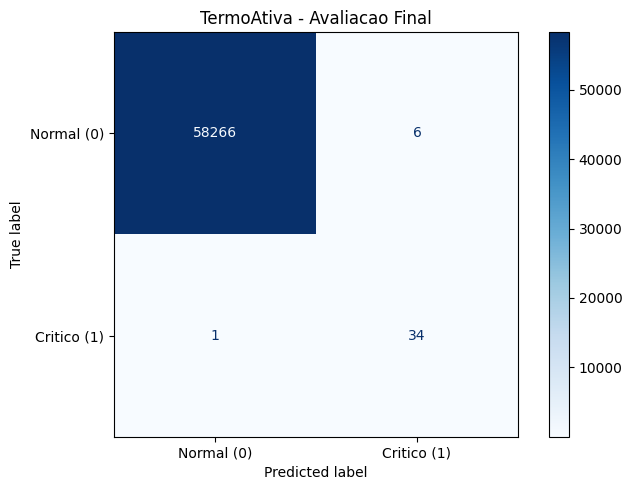


=== RELATORIO DE CLASSIFICACAO ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     58272
           1       0.85      0.97      0.91        35

    accuracy                           1.00     58307
   macro avg       0.92      0.99      0.95     58307
weighted avg       1.00      1.00      1.00     58307



In [29]:

# ===========================================
# TERMOATIVA - AVALIACAO FINAL
# ===========================================

# Calcula os scores no conjunto de teste
prob_teste = modelo_final.predict_proba(
    X_teste[features_finais]
)[:, 1]

# Aplica o limiar definido na validacao
y_pred_teste = (
    prob_teste >= limiar_final
).astype(int)

# Calcula as metricas
acuracia_final = accuracy_score(
    y_teste, y_pred_teste
)

precisao_final = precision_score(
    y_teste, y_pred_teste,
    zero_division=0
)

recall_final = recall_score(
    y_teste, y_pred_teste,
    zero_division=0
)

f1_final = f1_score(
    y_teste, y_pred_teste,
    zero_division=0
)

print("=== RESULTADOS FINAIS - TESTE ===")

print(f"Acuracia: {acuracia_final:.4f}")
print(f"Precisao: {precisao_final:.4f}")
print(f"Recall: {recall_final:.4f}")
print(f"F1-score: {f1_final:.4f}")

# Matriz de confusao
matriz_final = confusion_matrix(
    y_teste,
    y_pred_teste,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_final.ravel()

print("\n=== MATRIZ DE CONFUSAO ===")

print("Verdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

# Visualizacao
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=["Normal (0)", "Critico (1)"]
).plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("TermoAtiva - Avaliacao Final")
plt.tight_layout()
plt.show()

# Relatorio completo
print("\n=== RELATORIO DE CLASSIFICACAO ===")

print(classification_report(
    y_teste,
    y_pred_teste,
    labels=[0, 1],
    zero_division=0
))


In [30]:

# ===========================================
# TERMOATIVA - ANALISE DOS ERROS
# ===========================================

# Cria tabela de avaliacao
analise_teste = df_teste.copy()

analise_teste["previsao_modelo"] = y_pred_teste
analise_teste["score_modelo"] = prob_teste

# Identifica erros de classificacao
erros = analise_teste[
    analise_teste["nivel_alerta_ambiental"]
    != analise_teste["previsao_modelo"]
].copy()

# Separa os tipos de erros
falsos_negativos = erros[
    (erros["nivel_alerta_ambiental"] == 1)
    & (erros["previsao_modelo"] == 0)
]

falsos_positivos = erros[
    (erros["nivel_alerta_ambiental"] == 0)
    & (erros["previsao_modelo"] == 1)
]

print("=== ANALISE DOS ERROS ===")

print("Total de erros:", len(erros))
print("Falsos negativos:", len(falsos_negativos))
print("Falsos positivos:", len(falsos_positivos))

colunas_analise = [
    "cidade",
    "data_hora_utc",
    "temperatura_ar_celsius",
    "umidade_relativa_ar",
    "indice_calor_celsius",
    "score_modelo"
]

print("\n=== FALSOS NEGATIVOS ===")

if falsos_negativos.empty:
    print("Nenhum falso negativo encontrado.")
else:
    display(
        falsos_negativos[
            colunas_analise
        ].head(15).round(3)
    )

print("\n=== FALSOS POSITIVOS ===")

if falsos_positivos.empty:
    print("Nenhum falso positivo encontrado.")
else:
    display(
        falsos_positivos[
            colunas_analise
        ].head(15).round(3)
    )


=== ANALISE DOS ERROS ===
Total de erros: 7
Falsos negativos: 1
Falsos positivos: 6

=== FALSOS NEGATIVOS ===


,cidade,data_hora_utc,temperatura_ar_celsius,umidade_relativa_ar,indice_calor_celsius,score_modelo
51780,ARIRANHA,2025-03-14 17:00:00+00:00,33.9,54.0,39.568,0.988



=== FALSOS POSITIVOS ===


,cidade,data_hora_utc,temperatura_ar_celsius,umidade_relativa_ar,indice_calor_celsius,score_modelo
33660,BERTIOGA,2025-02-17 00:00:00+00:00,28.3,100.0,37.488,0.999
33691,BERTIOGA,2025-02-17 01:00:00+00:00,27.9,100.0,36.016,0.995
34187,RANCHARIA,2025-02-17 18:00:00+00:00,36.3,38.0,39.043,0.994
222960,BEBEDOURO,2025-10-07 16:00:00+00:00,38.7,21.0,37.838,0.996
288035,RANCHARIA,2025-12-26 18:00:00+00:00,36.9,35.0,39.158,0.997
288079,VALPARAISO,2025-12-26 19:00:00+00:00,37.3,31.0,38.560,0.994


In [31]:

# ===========================================
# TERMOATIVA - CLASSIFICADOR AMBIENTAL
# ===========================================

def classificar_ambiente(
    temperatura_ar_celsius,
    umidade_relativa_ar,
    hora_do_dia
):
    # Converte os valores recebidos
    temperatura = float(temperatura_ar_celsius)
    umidade = float(umidade_relativa_ar)
    hora = int(hora_do_dia)

    # Validacao das entradas
    if not np.isfinite([temperatura, umidade]).all():
        raise ValueError("Valores numericos invalidos.")

    if not -20 <= temperatura <= 55:
        raise ValueError("Temperatura fora da faixa aceita.")

    if not 0 <= umidade <= 100:
        raise ValueError("Umidade deve estar entre 0 e 100.")

    if not 1 <= hora <= 24:
        raise ValueError("Hora deve estar entre 1 e 24.")

    # Prepara os dados para o modelo
    entrada = pd.DataFrame([{
        "temperatura_ar_celsius": temperatura,
        "umidade_relativa_ar": umidade,
        "hora_do_dia": hora
    }])

    entrada = entrada[features_finais]

    # Classificacao por Machine Learning
    score = float(
        modelo_final.predict_proba(entrada)[0, 1]
    )

    alerta_ml = int(score >= limiar_final)

    # Verificacao fisica pelo indice da NOAA
    indice_calor = calcular_indice_calor(
        temperatura, umidade
    )

    alerta_noaa = int(
        indice_calor >= LIMIAR_CRITICO_C
    )

    # Alerta preventivo:
    # nenhuma das duas verificacoes e ignorada
    alerta_final = int(
        alerta_ml == 1 or alerta_noaa == 1
    )

    if alerta_final == 1:
        mensagem = (
            "ALERTA TERMICO: considere uma pausa, "
            "procure sombra e pontos de hidratacao."
        )
    else:
        mensagem = (
            "Sem alerta critico pelo criterio adotado. "
            "Mantenha os cuidados preventivos."
        )

    return {
        "temperatura_ar_celsius": temperatura,
        "umidade_relativa_ar": umidade,
        "hora_do_dia": hora,
        "indice_calor_celsius": round(
            indice_calor, 3
        ),
        "score_modelo": round(score, 6),
        "alerta_ml": alerta_ml,
        "alerta_noaa": alerta_noaa,
        "nivel_alerta_ambiental": alerta_final,
        "mensagem": mensagem
    }


print("Classificador ambiental criado!")


Classificador ambiental criado!


In [32]:

# ===========================================
# TERMOATIVA - EXPORTACAO DO MODELO
# ===========================================

import joblib
from pathlib import Path

# Pacote com modelo e configuracoes
artefato_modelo = {
    "modelo": modelo_final,
    "features": features_finais,
    "limiar_ml": limiar_final,
    "limiar_noaa_c": LIMIAR_CRITICO_C,
    "algoritmo": "Regressao Logistica",
    "origem_dados": "INMET - SP - 2025"
}

# Caminho do arquivo
caminho_modelo = Path(
    "/content/termoativa_modelo_ia.joblib"
)

# Exporta o modelo
joblib.dump(
    artefato_modelo,
    caminho_modelo,
    compress=3
)

print("Modelo exportado com sucesso!")
print("Arquivo:", caminho_modelo)

# Carrega novamente para conferir
modelo_carregado = joblib.load(caminho_modelo)

# Confere se as previsoes foram preservadas
amostra = X_validacao[
    features_finais
].head(5)

scores_originais = modelo_final.predict_proba(
    amostra
)

scores_carregados = (
    modelo_carregado["modelo"]
    .predict_proba(amostra)
)

assert np.allclose(
    scores_originais,
    scores_carregados
)

print("Verificacao concluida!")
print("Modelo carregado e previsoes preservadas.")


Modelo exportado com sucesso!
Arquivo: /content/termoativa_modelo_ia.joblib
Verificacao concluida!
Modelo carregado e previsoes preservadas.


In [33]:

# ===========================================
# TERMOATIVA - SIMULACAO DE ALERTAS
# ===========================================

import json

# Tres situacoes ambientais ilustrativas
cenarios = [
    {
        "cenario": "Condicao amena",
        "temperatura": 27.0,
        "umidade": 55.0,
        "hora": 8
    },
    {
        "cenario": "Calor extremo",
        "temperatura": 36.0,
        "umidade": 70.0,
        "hora": 14
    },
    {
        "cenario": "Caso proximo ao limiar - Ariranha",
        "temperatura": 33.9,
        "umidade": 54.0,
        "hora": 14
    }
]

resultados = []

for cenario in cenarios:

    resultado = classificar_ambiente(
        cenario["temperatura"],
        cenario["umidade"],
        cenario["hora"]
    )

    resultado["cenario"] = cenario["cenario"]
    resultados.append(resultado)

# Organiza a tabela
df_simulacao = pd.DataFrame(resultados)

print("=== SIMULACAO TERMOATIVA ===")

display(df_simulacao[[
    "cenario",
    "indice_calor_celsius",
    "score_modelo",
    "alerta_ml",
    "alerta_noaa",
    "nivel_alerta_ambiental"
]])

# Verifica o modelo carregado do arquivo Joblib
artefato_recarregado = joblib.load(caminho_modelo)

entrada = pd.DataFrame([{
    "temperatura_ar_celsius": 33.9,
    "umidade_relativa_ar": 54.0,
    "hora_do_dia": 14
}])

score_recarregado = (
    artefato_recarregado["modelo"]
    .predict_proba(
        entrada[artefato_recarregado["features"]]
    )[0, 1]
)

print("\n=== MODELO EXPORTADO ===")
print("Score do arquivo Joblib:", round(
    float(score_recarregado), 6
))

print("\n=== EXEMPLO DE RESPOSTA JSON ===")
print(json.dumps(
    resultados[-1],
    indent=4,
    ensure_ascii=False
))


=== SIMULACAO TERMOATIVA ===


,cenario,indice_calor_celsius,score_modelo,alerta_ml,alerta_noaa,nivel_alerta_ambiental
0,Condicao amena,27.735,0.000000,0,0,0
1,Calor extremo,54.151,1.000000,1,1,1
2,Caso proximo ao limiar - Ariranha,39.568,0.987744,0,1,1



=== MODELO EXPORTADO ===
Score do arquivo Joblib: 0.987744

=== EXEMPLO DE RESPOSTA JSON ===
{
    "temperatura_ar_celsius": 33.9,
    "umidade_relativa_ar": 54.0,
    "hora_do_dia": 14,
    "indice_calor_celsius": 39.568,
    "score_modelo": 0.987744,
    "alerta_ml": 0,
    "alerta_noaa": 1,
    "nivel_alerta_ambiental": 1,
    "mensagem": "ALERTA TERMICO: considere uma pausa, procure sombra e pontos de hidratacao.",
    "cenario": "Caso proximo ao limiar - Ariranha"
}


In [36]:

# ===========================================
# TERMOATIVA - SALVAR ARTEFATOS NO DRIVE
# ===========================================

from google.colab import drive
from pathlib import Path
import shutil
import json

# Conecta ao Google Drive
drive.mount("/content/drive")

# Pasta do projeto
pasta_projeto = Path(
    "/content/drive/MyDrive/TermoAtiva_IA"
)

pasta_projeto.mkdir(
    parents=True,
    exist_ok=True
)

# Salva o modelo treinado
destino_modelo = (
    pasta_projeto / "termoativa_modelo_ia.joblib"
)

shutil.copy2(
    caminho_modelo,
    destino_modelo
)

# Salva um exemplo de resposta JSON
destino_json = (
    pasta_projeto / "exemplo_alerta.json"
)

with open(
    destino_json,
    "w",
    encoding="utf-8"
) as arquivo:
    json.dump(
        resultados[-1],
        arquivo,
        ensure_ascii=False,
        indent=4
    )

# Confirma os arquivos criados
print("=== ARQUIVOS SALVOS ===")

for arquivo in pasta_projeto.iterdir():
    print(
        arquivo.name,
        "-",
        round(arquivo.stat().st_size / 1024, 2),
        "KB"
    )


Mounted at /content/drive
=== ARQUIVOS SALVOS ===
termoativa_modelo_ia.joblib - 1.11 KB
exemplo_alerta.json - 0.37 KB


In [37]:

# ===========================================
# TERMOATIVA - EXPORTAR DATASET TRATADO
# ===========================================

from pathlib import Path

pasta_projeto = Path(
    "/content/drive/MyDrive/TermoAtiva_IA"
)

pasta_projeto.mkdir(
    parents=True,
    exist_ok=True
)

# Colunas utilizadas e documentadas
colunas_exportacao = [
    "estacao",
    "cidade",
    "data_hora_utc",
    "temperatura_ar_celsius",
    "umidade_relativa_ar",
    "hora_do_dia",
    "radiacao_global_kj_m2",
    "indice_calor_celsius",
    "nivel_alerta_ambiental"
]

# Copia os dados consolidados
dataset_final = df_sp[
    colunas_exportacao
].copy()

# Exporta o CSV
caminho_dataset = (
    pasta_projeto / "termoativa_dataset_tratado.csv"
)

dataset_final.to_csv(
    caminho_dataset,
    index=False,
    encoding="utf-8"
)

print("=== DATASET EXPORTADO ===")
print("Arquivo:", caminho_dataset)
print("Registros:", len(dataset_final))
print("Colunas:", len(dataset_final.columns))

print("\nDistribuicao do target:")
print(
    dataset_final["nivel_alerta_ambiental"]
    .value_counts()
)

print("\nTamanho do arquivo:")
print(
    round(
        caminho_dataset.stat().st_size / 1024**2,
        2
    ),
    "MB"
)

print("\nExportacao concluida!")


=== DATASET EXPORTADO ===
Arquivo: /content/drive/MyDrive/TermoAtiva_IA/termoativa_dataset_tratado.csv
Registros: 292745
Colunas: 9

Distribuicao do target:
nivel_alerta_ambiental
0    292613
1       132
Name: count, dtype: int64

Tamanho do arquivo:
22.16 MB

Exportacao concluida!


In [38]:

# ===========================================
# TERMOATIVA - INTERFACE DE DEMONSTRACAO
# ===========================================

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Campos da interface
campo_temperatura = widgets.BoundedFloatText(
    value=33.9,
    min=-20,
    max=55,
    step=0.1,
    description="Temp. (°C):",
    style={"description_width": "120px"}
)

campo_umidade = widgets.BoundedFloatText(
    value=54.0,
    min=0,
    max=100,
    step=1,
    description="Umidade (%):",
    style={"description_width": "120px"}
)

campo_hora = widgets.IntSlider(
    value=14,
    min=1,
    max=24,
    description="Hora:",
    style={"description_width": "120px"}
)

# Botao para executar a classificacao
botao = widgets.Button(
    description="Analisar risco termico",
    button_style="primary",
    icon="thermometer"
)

# Area onde aparecera o resultado
area_resultado = widgets.Output()


def executar_analise(_):

    with area_resultado:

        clear_output(wait=True)

        try:
            resultado = classificar_ambiente(
                campo_temperatura.value,
                campo_umidade.value,
                campo_hora.value
            )

            risco = resultado[
                "nivel_alerta_ambiental"
            ]

            if risco == 1:
                titulo = "ALERTA TERMICO CRITICO"
                cor = "#c0392b"
            else:
                titulo = "SEM ALERTA CRITICO"
                cor = "#17804a"

            display(HTML(f"""
                <div style="
                    border: 2px solid {cor};
                    border-radius: 12px;
                    padding: 18px;
                    margin-top: 15px;
                ">
                    <h2 style="color: {cor};">
                        {titulo}
                    </h2>

                    <p>
                        <b>Indice de calor:</b>
                        {resultado['indice_calor_celsius']} °C
                    </p>

                    <p>
                        <b>Score da IA:</b>
                        {resultado['score_modelo']:.4f}
                    </p>

                    <p>
                        <b>Alerta do modelo:</b>
                        {resultado['alerta_ml']}
                    </p>

                    <p>
                        <b>Alerta pela NOAA:</b>
                        {resultado['alerta_noaa']}
                    </p>

                    <p>
                        <b>Orientacao:</b>
                        {resultado['mensagem']}
                    </p>
                </div>
            """))

        except (ValueError, TypeError) as erro:
            print("Erro na entrada:", erro)


# Conecta o botao a funcao
botao.on_click(executar_analise)

# Monta a interface
interface = widgets.VBox([
    widgets.HTML(
        "<h2>TermoAtiva - Monitoramento Termico</h2>"
        "<p>Informe as condicoes ambientais "
        "para simular um alerta preventivo.</p>"
    ),
    campo_temperatura,
    campo_umidade,
    campo_hora,
    botao,
    area_resultado
])

display(interface)


In [46]:

# ===========================================
# TERMOATIVA - DOCUMENTACAO README
# ===========================================

from pathlib import Path

pasta_projeto = Path(
    "/content/drive/MyDrive/TermoAtiva_IA"
)

if not pasta_projeto.exists():
    raise RuntimeError(
        "Monte o Google Drive antes de executar."
    )

readme = """
# TermoAtiva — Inteligência Artificial & Machine Learning

## FIAP — Global Solution 2026.2
**Tema:** CitizenTech

**Disciplina:** Inteligência Artificial & Machine Learning

**Projeto:** TermoAtiva

**Equipe:**
Jonathan Henrique da Silva — RM: 561139
Musashi Nascimento Mabuti — RM: 559444
Marcos Vinicius Gonçalves Santos — RM: 560062
Felipe Gimenes — RM: 99799

**Repositório GitHub:** https://github.com/Quinhos/GS_Machine_Learning.git

## 1. Apresentação do projeto

A TermoAtiva é uma plataforma de monitoramento
microclimático urbano voltada à identificação de
condições ambientais de calor extremo.

A solução busca apoiar trabalhadores a céu aberto,
entregadores, garis, pedestres, idosos e agentes
comunitários por meio de alertas preventivos.

O projeto também prevê um módulo comunitário com
informações sobre pontos de hidratação, sombra e
refúgio.

ODS relacionados:
- ODS 3 — Saúde e Bem-Estar
- ODS 10 — Redução das Desigualdades
- ODS 11 — Cidades e Comunidades Sustentáveis

## 2. Problema de Machine Learning

Classificar condições de risco térmico ambiental
a partir de medições meteorológicas.

Algoritmo: Regressão Logística.

Tipo de problema: classificação binária.

Target: nivel_alerta_ambiental

- Classe 0: sem alerta crítico pelo critério adotado
- Classe 1: risco térmico crítico

O sistema não realiza diagnósticos clínicos nem
avalia a saúde individual dos cidadãos.

## 3. Origem dos dados

Fonte: Instituto Nacional de Meteorologia (INMET).

Período: ano de 2025.

Região: estado de São Paulo.

Estações meteorológicas utilizadas: 40.

Fonte oficial:
https://portal.inmet.gov.br/dadoshistoricos

Os dados meteorológicos são públicos e reais.

A coluna de classificação foi calculada no projeto
a partir da metodologia do Heat Index da NOAA.

Referência:
https://www.wpc.ncep.noaa.gov/html/heatindex_equation.shtml

## 4. Construção do dataset

Registros consolidados: 292.745.

Registros sem alerta crítico: 292.613.

Registros críticos: 132.

O limite inicial para a classe crítica foi um
Heat Index de 103°F (aproximadamente 39,44°C),
correspondente à categoria Danger do NWS.

Este critério representa uma condição ambiental
de referência, não a ocorrência de um problema
de saúde.

## 5. Preparação dos dados

Foram realizadas as seguintes operações:

- Importação dos CSVs históricos do INMET.
- Identificação das estações paulistas.
- Conversão das medições para valores numéricos.
- Conferência de valores ausentes e inconsistentes.
- Tratamento de registros inválidos.
- Conversão dos horários UTC.
- Cálculo do índice de calor NOAA.
- Criação do target binário.
- Consolidação das estações.

O dataset tratado está disponível no arquivo:

termoativa_dataset_tratado.csv

## 6. Variáveis do modelo final

- temperatura_ar_celsius
- umidade_relativa_ar
- hora_do_dia

A variável de horário utiliza o horário local de
São Paulo, representado de 1 a 24.

Também foi avaliada a radiação solar global do
INMET, mas sua inclusão não trouxe melhoria
relevante na validação.

A radiação global não foi tratada como índice UV.

O índice de calor não foi utilizado como feature,
pois já determina o target do experimento.

## 7. Treinamento

Foi utilizado o Scikit-learn com:

- StandardScaler
- Pipeline
- LogisticRegression
- class_weight="balanced"
- max_iter=2000
- random_state=42

A separação foi realizada por dias completos,
com estratificação entre dias com e sem registros
críticos:

- Treinamento: 176.362 registros
- Validação: 58.076 registros
- Teste: 58.307 registros

O limiar de classificação foi ajustado usando
somente o conjunto de validação.

Limiar final: aproximadamente 0,992007.

## 8. Avaliação final

Resultados no conjunto de teste:

- Acurácia: 99,99%
- Precisão: 85,00%
- Recall: 97,14%
- F1-score: 90,67%

Matriz de confusão:

- Verdadeiros negativos: 58.266
- Falsos positivos: 6
- Falsos negativos: 1
- Verdadeiros positivos: 34

A métrica prioritária foi o Recall da classe 1,
pois o objetivo é reduzir condições críticas
não identificadas.

## 9. Integração com a TermoAtiva

O modelo foi exportado com Joblib.

Arquivo:
termoativa_modelo_ia.joblib

Foi desenvolvida uma função Python que recebe
temperatura, umidade e horário e retorna a
classificação ambiental.

A demonstração no Google Colab inclui uma
interface interativa e respostas estruturadas.

O protótipo combina o resultado do modelo com
uma verificação direta do índice de calor NOAA.

Essa verificação complementar não faz parte das
métricas da Regressão Logística.

A comunicação efetiva com o aplicativo mobile
e os totens depende de integração posterior.

## 10. Como executar

1. Abrir o notebook no Google Colab.
2. Executar as células na ordem apresentada.
3. Baixar os dados históricos do INMET pelo
   próprio notebook.
4. Realizar a preparação e análise dos dados.
5. Executar o treinamento e a avaliação.
6. Testar os cenários ambientais.
7. Executar a interface interativa.
8. Salvar os artefatos no Google Drive.

Principais bibliotecas:
Pandas, NumPy, Matplotlib, Scikit-learn,
Joblib, Requests e ipywidgets.

## 11. Limitações

- Os alertas críticos são eventos raros na base.
- A validação envolve somente 35 registros
  críticos no conjunto final de teste.
- Dias consecutivos podem pertencer ao mesmo
  episódio de calor, mesmo após a separação.
- O target é derivado de uma regra física NOAA.
- As métricas medem concordância com essa regra,
  não resultados reais sobre a saúde das pessoas.
- Os scores do modelo não foram calibrados como
  probabilidades reais de risco.
- O Heat Index de referência considera condições
  à sombra e não representa integralmente a
  exposição ao sol direto.
- O modelo classifica condições fornecidas como
  entrada; não produz previsão meteorológica.
- Alertas para as próximas horas exigem fornecer
  estimativas meteorológicas desses horários.

## 12. Conclusão

O projeto demonstrou a aplicação de Regressão
Logística na classificação de risco térmico
ambiental utilizando dados reais do INMET.

O modelo alcançou Recall de 97,14% na avaliação
final, identificando 34 dos 35 registros críticos.

A solução oferece uma prova de conceito de IA
para apoiar alertas ambientais preventivos,
sem realizar diagnósticos individuais.
"""

caminho_readme = pasta_projeto / "README.md"

caminho_readme.write_text(
    readme.strip() + "\n",
    encoding="utf-8"
)

print("README criado com sucesso!")
print("Arquivo:", caminho_readme)
print("Linhas:", len(readme.strip().splitlines()))


README criado com sucesso!
Arquivo: /content/drive/MyDrive/TermoAtiva_IA/README.md
Linhas: 241


In [45]:

# ===========================================
# TERMOATIVA - VERIFICACAO DA ENTREGA
# ===========================================

arquivos_obrigatorios = [
    "README.md",
    "termoativa_dataset_tratado.csv",
    "termoativa_modelo_ia.joblib"
]

print("=== VERIFICACAO DOS ARQUIVOS ===")

for nome in arquivos_obrigatorios:
    arquivo = pasta_projeto / nome

    if arquivo.is_file():
        print(f"[OK] {nome}")
    else:
        print(f"[PENDENTE] {nome}")

print("\n=== INICIO DO README ===")

conteudo = caminho_readme.read_text(
    encoding="utf-8"
)

print(conteudo[:1500])

print("\n=== RESULTADO ===")

assert all(
    (pasta_projeto / nome).is_file()
    for nome in arquivos_obrigatorios
)

print("Artefatos principais presentes no Drive!")


=== VERIFICACAO DOS ARQUIVOS ===
[OK] README.md
[OK] termoativa_dataset_tratado.csv
[OK] termoativa_modelo_ia.joblib

=== INICIO DO README ===
# TermoAtiva — Inteligência Artificial & Machine Learning

## FIAP — Global Solution 2026.2
**Tema:** CitizenTech

**Disciplina:** Inteligência Artificial & Machine Learning

**Projeto:** TermoAtiva

**Equipe:** 
Jonathan Henrique da Silva — RM: 561139
Musashi Nascimento Mabuti — RM: 559444
Marcos Vinicius Gonçalves Santos — RM: 560062
Felipe Gimenes — RM: 99799

**Repositório GitHub:** [Inserir link]

## 1. Apresentação do projeto

A TermoAtiva é uma plataforma de monitoramento
microclimático urbano voltada à identificação de
condições ambientais de calor extremo.

A solução busca apoiar trabalhadores a céu aberto,
entregadores, garis, pedestres, idosos e agentes
comunitários por meio de alertas preventivos.

O projeto também prevê um módulo comunitário com
informações sobre pontos de hidratação, sombra e
refúgio.

ODS relacionados:
- ODS 3 — S